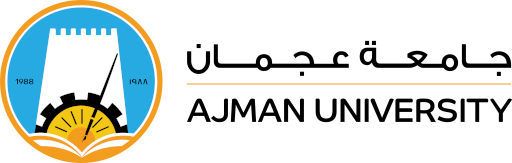

<table style="margin-left: 0; margin-right: auto;">
  <tr>
    <td><b>College:</b></td>
    <td>Engineering and Information Technology</td>
  </tr>
  <tr>
    <td><b>Department:</b></td>
    <td>Information Technology</td>
  </tr>
  <tr>
    <td><b>Program:</b></td>
    <td>Data Analytics and Artificial Intelligence</td>
  </tr>
  <tr>
    <td><b>Academic Semester:</b></td>
    <td>Spring 2025-2026</td>
  </tr>
  <tr>
    <td><b>Course:</b></td>
    <td>DAT405 Machine Learning Lab</td>
  </tr>
  <tr>
    <td><b>Course Instructor:</b></td>
    <td>Prof. Mahmoud AlShboul</td>
  </tr>
</table>


# **Lab 9 - Ensemble Methods & Hyperparameter Tuning**

## Ensemble Methods

Ensemble methods are machine learning techniques that combine multiple models (often called weak learners) to produce a stronger and more accurate model. Instead of relying on one model’s prediction, ensemble learning takes the collective decision of several models — much like how a group of experts often makes better decisions than a single expert. Single models (like a decision tree or logistic regression) may:

- Overfit (perform well on training data but poorly on test data),
- Underfit (fail to capture patterns),
- Or simply be unstable (small data changes can cause big prediction changes).

Ensemble methods help by:
- Reducing variance (less overfitting)
- Reducing bias (better learning of true patterns)
- Improving prediction stability and accuracy

### Major Types of Ensemble Methods
#### Bagging (Bootstrap Aggregating)

Trains multiple models (usually of the same type, e.g., Decision Trees) on different random subsets of the training data. Predictions are then averaged (for regression) or voted (for classification). Example:

- Random Forest: A collection of many decision trees trained on random subsets of data and features. The final prediction is the majority vote (classification) or average (regression).

Goal: Reduce variance (makes model more stable).

#### Boosting

Builds models sequentially, where each new model tries to correct the errors made by previous models. Focuses more on samples that were previously misclassified. Examples:

- AdaBoost (Adaptive Boosting)
- Gradient Boosting Machines (GBM)
- XGBoost, LightGBM, CatBoost

Goal: Reduce bias (makes model more accurate).

#### Stacking (Stacked Generalization)

Trains different kinds of models (e.g., Logistic Regression, Random Forest, SVM). Their predictions are then fed into a “meta-model”, which learns how to best combine their outputs. Example:

- Level 1: Random Forest, SVM, and Neural Network
- Level 2 (meta-learner): Logistic Regression that learns how to blend them.

Goal: Combine the strengths of various model types.

In [84]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer, load_diabetes
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from xgboost import XGBClassifier, XGBRegressor

from sklearn.metrics import accuracy_score, classification_report, root_mean_squared_error, r2_score, confusion_matrix

pd.set_option('display.max_columns', None)

In [85]:
# Load the Breast Cancer dataset from scikit-learn
# This dataset is commonly used for binary classification tasks.
# It contains information about various features (e.g., mean radius, texture, etc.)
# extracted from breast mass images and a target variable indicating if the tumor is malignant (1) or benign (0).
cancer = load_breast_cancer()

# Create a Pandas DataFrame from the dataset.
# The dataset's features are stored in 'cancer["data"]', which is a NumPy array of shape (n_samples, n_features).
# The target values (malignant or benign) are stored separately in 'cancer["target"]'.
# We use np.c_ to concatenate these two arrays column-wise — meaning, the feature data and the target column are merged into one 2D array.
df = pd.DataFrame(
    np.c_[cancer['data'], cancer['target']],         # Combine feature data and target labels side by side
    columns=np.append(cancer['feature_names'], ['target'])  # Create column names: all feature names + one for the target
)

# Display the first 10 rows of the DataFrame to get an overview of the dataset.
# This helps verify that the data and target values have been correctly merged and labeled.
df.head(10)


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,radius error,texture error,perimeter error,area error,smoothness error,compactness error,concavity error,concave points error,symmetry error,fractal dimension error,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.30010,0.14710,0.2419,0.07871,1.0950,0.9053,8.589,153.40,0.006399,0.04904,0.05373,0.01587,0.03003,0.006193,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0.0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.08690,0.07017,0.1812,0.05667,0.5435,0.7339,3.398,74.08,0.005225,0.01308,0.01860,0.01340,0.01389,0.003532,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0.0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.19740,0.12790,0.2069,0.05999,0.7456,0.7869,4.585,94.03,0.006150,0.04006,0.03832,0.02058,0.02250,0.004571,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0.0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.24140,0.10520,0.2597,0.09744,0.4956,1.1560,3.445,27.23,0.009110,0.07458,0.05661,0.01867,0.05963,0.009208,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0.0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.19800,0.10430,0.1809,0.05883,0.7572,0.7813,5.438,94.44,0.011490,0.02461,0.05688,0.01885,0.01756,0.005115,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0.0
5,12.45,15.70,82.57,477.1,0.12780,0.17000,0.15780,0.08089,0.2087,0.07613,0.3345,0.8902,2.217,27.19,0.007510,0.03345,0.03672,0.01137,0.02165,0.005082,15.47,23.75,103.40,741.6,0.1791,0.5249,0.5355,0.1741,0.3985,0.12440,0.0
6,18.25,19.98,119.60,1040.0,0.09463,0.10900,0.11270,0.07400,0.1794,0.05742,0.4467,0.7732,3.180,53.91,0.004314,0.01382,0.02254,0.01039,0.01369,0.002179,22.88,27.66,153.20,1606.0,0.1442,0.2576,0.3784,0.1932,0.3063,0.08368,0.0
7,13.71,20.83,90.20,577.9,0.11890,0.16450,0.09366,0.05985,0.2196,0.07451,0.5835,1.3770,3.856,50.96,0.008805,0.03029,0.02488,0.01448,0.01486,0.005412,17.06,28.14,110.60,897.0,0.1654,0.3682,0.2678,0.1556,0.3196,0.11510,0.0
8,13.00,21.82,87.50,519.8,0.12730,0.19320,0.18590,0.09353,0.2350,0.07389,0.3063,1.0020,2.406,24.32,0.005731,0.03502,0.03553,0.01226,0.02143,0.003749,15.49,30.73,106.20,739.3,0.1703,0.5401,0.5390,0.2060,0.4378,0.10720,0.0
9,12.46,24.04,83.97,475.9,0.11860,0.23960,0.22730,0.08543,0.2030,0.08243,0.2976,1.5990,2.039,23.94,0.007149,0.07217,0.07743,0.01432,0.01789,0.010080,15.09,40.68,97.65,711.4,0.1853,1.0580,1.1050,0.2210,0.4366,0.20750,0.0


In [86]:
# Count the occurrences of each unique value in the 'target' column.
# The 'target' column represents the classification labels for the dataset:
#   - 0 means the tumor is *malignant* (cancerous)
#   - 1 means the tumor is *benign* (non-cancerous)
#
# The value_counts() method returns how many samples belong to each class.
# This is useful for checking if the dataset is balanced (equal number of benign and malignant samples)
# or imbalanced (one class dominates the other), which can affect model performance.
df['target'].value_counts()

target
1.0    357
0.0    212
Name: count, dtype: int64

In [87]:
# Separate features (X) and target labels (y) from the dataset

# 'df.drop('target', axis=1)' removes the 'target' column from the DataFrame.
# This gives us all the input features used for prediction (such as mean radius, mean texture, etc.).
X = df.drop('target', axis=1)

# 'df['target']' selects the target column, which contains the class labels:
# 0 = malignant (cancerous), 1 = benign (non-cancerous)
y = df['target']


# Split the dataset into training and testing sets

# train_test_split() randomly divides the data into training and testing subsets.
# Parameters:
#   X, y             → the features and labels to split
#   test_size=0.3    → 30% of the data will be used for testing, 70% for training
#   random_state=42  → ensures reproducibility (same random split each time you run the code)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)


## Decision Tree Classifier
A Decision Tree is a popular supervised machine learning algorithm used for both classification and regression tasks. It works by splitting the dataset into smaller subsets based on feature values, ultimately leading to a tree structure where each internal node represents a feature, each branch represents a decision rule, and each leaf node represents an outcome or prediction.

In [88]:
from sklearn.tree import DecisionTreeClassifier

In [89]:
dtree = DecisionTreeClassifier(random_state=42)  # You can adjust hyperparameters here
dtree.fit(X_train, y_train)

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary ` for details.",42
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current

In [90]:
y_pred = dtree.predict(X_test)

In [91]:
accuracy = accuracy_score(y_test, y_pred)
conf_matrix = confusion_matrix(y_test, y_pred)
class_report = classification_report(y_test, y_pred)

print(f'Accuracy: {accuracy * 100:.2f}%')
print('Confusion Matrix:')
print(conf_matrix)
print('Classification Report:')
print(class_report)

Accuracy: 94.15%
Confusion Matrix:
[[ 60   3]
 [  7 101]]
Classification Report:
              precision    recall  f1-score   support

         0.0       0.90      0.95      0.92        63
         1.0       0.97      0.94      0.95       108

    accuracy                           0.94       171
   macro avg       0.93      0.94      0.94       171
weighted avg       0.94      0.94      0.94       171



In [92]:
from sklearn.tree import plot_tree

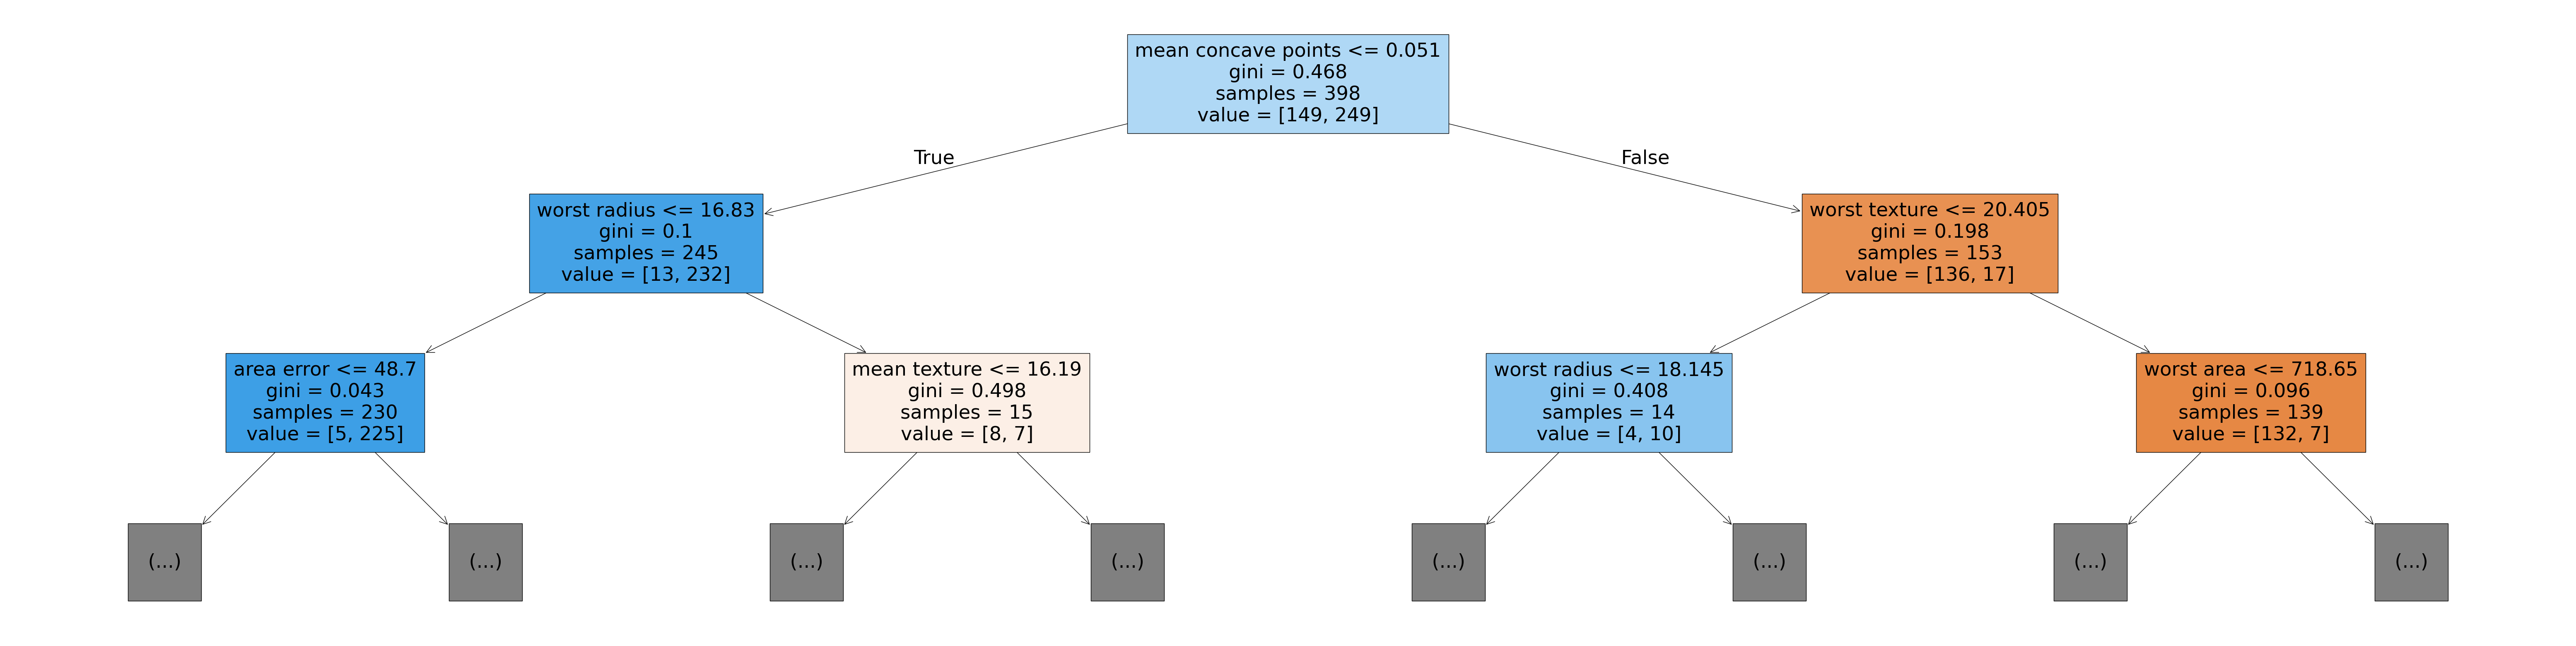

In [93]:
plt.figure(figsize=(80,20))
plot_tree(dtree, feature_names=X_train.columns, max_depth=2, filled=True);

The Gini index value shown in each box represents the impurity measure used by the decision tree to determine the best feature and the optimal split point at each node. The Gini index helps the algorithm decide how to partition the data at every stage. A lower Gini index indicates a more effective split, meaning the resulting groups are more homogeneous (contain more instances of the same class). A Gini index of 0 represents a perfect split, where all instances in a node belong to a single class.

A perfect split has a Gini index of 0, meaning all elements in a node belong to a single class. As the classes in a node become more mixed, the Gini index increases, up to a maximum value when classes are evenly distributed (i.e., the node is maximally impure).

The Gini index is often compared with entropy (another impurity measure). While both serve the same purpose in identifying the best splits, the Gini index is computationally simpler and thus commonly used in decision trees.

In [94]:
dtree.tree_.max_depth

7

Based on the gini index computations, a decision tree assigns an "importance" value to each feature. These values can be used to interpret the results given by a decision tree.

In [95]:
import seaborn as sns

In [96]:
importances = dtree.feature_importances_
importances

array([0.        , 0.02288528, 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.70583856, 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.01356259, 0.00200417,
       0.        , 0.00715165, 0.01716396, 0.        , 0.        ,
       0.07018674, 0.11406234, 0.        , 0.0366527 , 0.01049202,
       0.        , 0.        , 0.        , 0.        , 0.        ])

In [97]:
feature_names = X.columns
feature_importance_df = pd.DataFrame({'Feature': feature_names, 'Importance': importances})

In [98]:
feature_importance_df = feature_importance_df.sort_values(by='Importance', ascending=False)

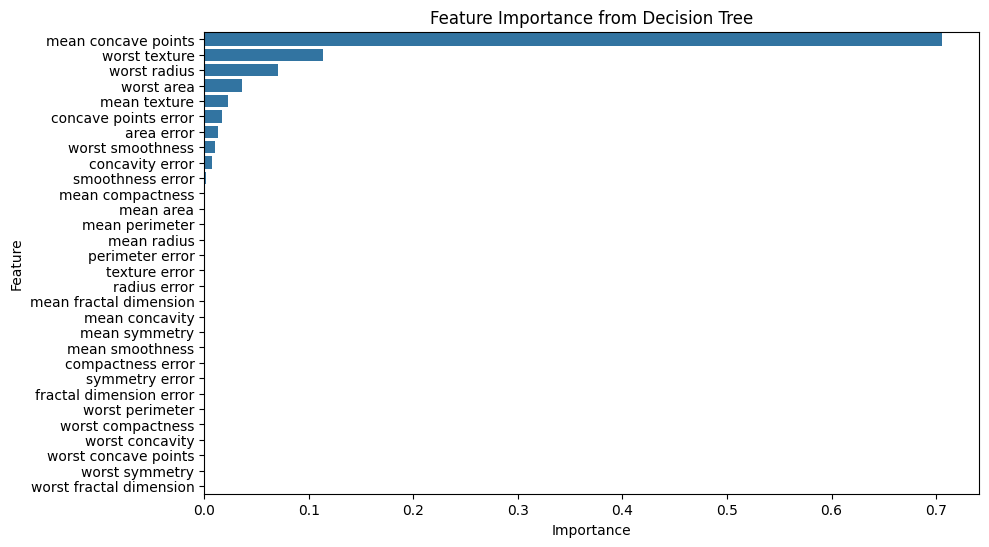

In [99]:
plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=feature_importance_df)
plt.title('Feature Importance from Decision Tree')
plt.show()

## Random Forest Classifier

Tuning the hyperparameters of a single decision tree can provide some performance gains, but a more powerful approach involves combining the predictions of multiple decision trees, each trained with slight variations in parameters and data. This ensemble method is known as a Random Forest.

The core concept behind Random bagging methods is that each individual decision tree will likely make different types of errors and is sensitive to changes in the dataset. By aggregating the predictions of multiple trees (usually through majority voting for classification or averaging for regression), these errors tend to cancel out, leading to a more accurate and stable model. This phenomenon is often referred to as the "wisdom of the crowd", where collective decision-making is generally more reliable than relying on a single model.

A random forest works by averaging/combining the results of several decision trees:

<img src="https://1.bp.blogspot.com/-Ax59WK4DE8w/YK6o9bt_9jI/AAAAAAAAEQA/9KbBf9cdL6kOFkJnU39aUn4m8ydThPenwCLcBGAsYHQ/s0/Random%2BForest%2B03.gif" width="640">


### Random Forests

Random Forest is an bagging method that combines multiple decision trees to improve model performance and reduce overfitting. Each tree in the forest is trained on a random subset of the data (bootstrapping) and the final prediction is made by averaging (for regression) or voting (for classification) across all trees.

#### Key Concept: Feature Randomization

In a Random Forest, when choosing a feature to split a node, instead of considering all available features, the algorithm randomly selects a subset of features to choose from. This helps decorrelate the trees and reduce overfitting.

- **At each node**, if there are $n$ features available, a random subset of $k$ features is selected, where $k < n$
- **For large $n$**, typically $k = \sqrt{n}$

This randomization helps to ensure that the trees are diverse, improving the overall accuracy of the model.

In [100]:
from sklearn.ensemble import RandomForestClassifier

In [101]:
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric

In [102]:
y_pred = rf_model.predict(X_test)

In [103]:
accuracy = accuracy_score(y_test, y_pred)
conf_matrix = confusion_matrix(y_test, y_pred)
class_report = classification_report(y_test, y_pred)

In [104]:
print(f'Accuracy: {accuracy * 100:.2f}%')
print('Confusion Matrix:')
print(conf_matrix)
print('Classification Report:')
print(class_report)

Accuracy: 97.08%
Confusion Matrix:
[[ 59   4]
 [  1 107]]
Classification Report:
              precision    recall  f1-score   support

         0.0       0.98      0.94      0.96        63
         1.0       0.96      0.99      0.98       108

    accuracy                           0.97       171
   macro avg       0.97      0.96      0.97       171
weighted avg       0.97      0.97      0.97       171



We can can access individual decision trees using `model.estimators_`

In [105]:
rf_model.estimators_[0]

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",'sqrt'
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary ` for details.",1608637542
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at t

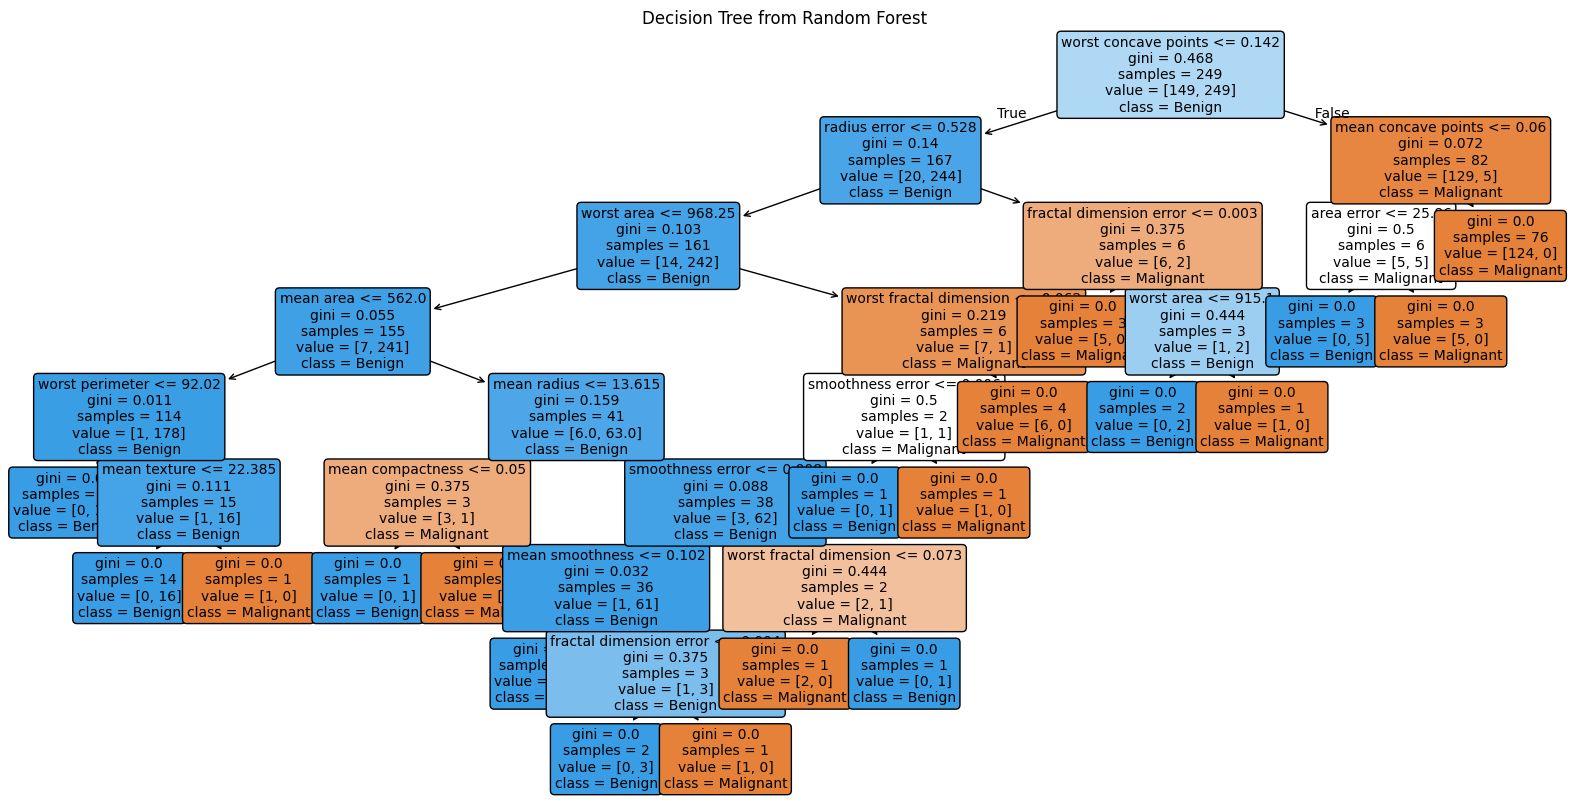

In [106]:
plt.figure(figsize=(20, 10))  # Adjust the figure size as needed
plot_tree(rf_model.estimators_[0], feature_names=X.columns, filled=True, rounded=True, class_names=['Malignant', 'Benign'], fontsize=10)
plt.title('Decision Tree from Random Forest')
plt.show()

And the feature importance:

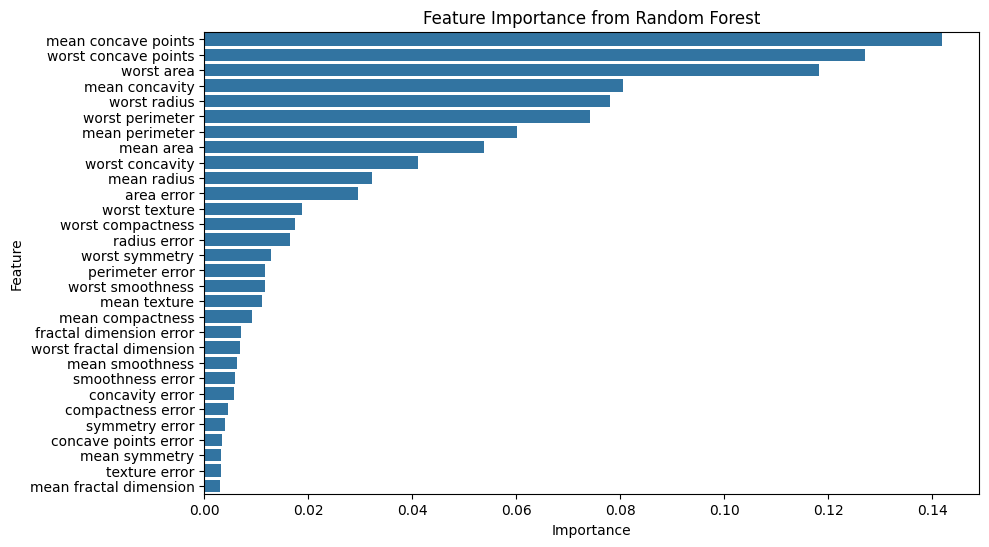

In [107]:
importances = rf_model.feature_importances_
feature_names = X.columns
feature_importance_df = pd.DataFrame({'Feature': feature_names, 'Importance': importances})
feature_importance_df = feature_importance_df.sort_values(by='Importance', ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=feature_importance_df)
plt.title('Feature Importance from Random Forest')
plt.show()

## XGBoost Classifier

XGBoost (Extreme Gradient Boosting) is a powerful and efficient machine learning algorithm based on the gradient boosting framework. It is widely used for supervised learning tasks, particularly in classification and regression problems.

XGBoost (Extreme Gradient Boosting) is an efficient and scalable implementation of gradient boosting, an ensemble method that builds models sequentially. Each tree is trained to predict the errors (residuals) of the previous tree, which makes it a powerful technique for regression and classification tasks.

### Key Concept: Boosting and Residuals

XGBoost works as follows:

1. **Sequential Tree Building**: Each new tree is trained to predict the **residuals** (errors) of the previous trees. This means each tree in the sequence focuses on the mistakes made by the earlier trees.

2. **Focus on Misclassified Examples**: The algorithm adjusts the weights of the misclassified examples so that subsequent trees are more likely to focus on these harder-to-predict samples.

This sequential learning process enables XGBoost to effectively reduce bias and improve predictive accuracy, especially when dealing with complex data.


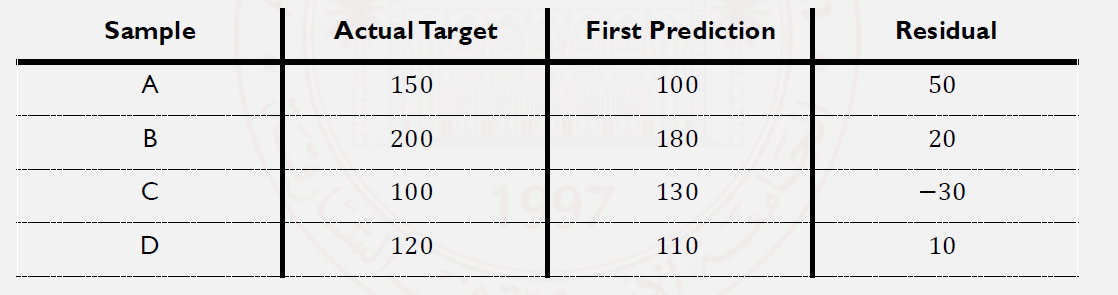

In [108]:
# !pip install xgboost

In [109]:
from xgboost import XGBClassifier

In [110]:
xgb_model = XGBClassifier(use_label_encoder=False)
xgb_model.fit(X_train, y_train)

/home/ali/Documents/AU/Assistant Instructor/202520/DAT405 Machine Learning/Labs/.venv/lib/python3.13/site-packages/xgboost/training.py:200: UserWarning: [10:17:26] WARNING: /__w/xgboost/xgboost/src/learner.cc:782: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


,"objective objective: typing.Union[str, xgboost.sklearn._SklObjWProto, typing.Callable[[typing.Any, typing.Any], typing.Tuple[numpy.ndarray, numpy.ndarray]], NoneType]Specify the learning task and the corresponding learning objective or a customobjective function to be used.For custom objective, see :doc:`/tutorials/custom_metric_obj` and:ref:`custom-obj-metric` for more information, along with the end note forfunction signatures.",'binary:logistic'
,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API `... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,False
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes 

In [111]:
y_pred = xgb_model.predict(X_test)

In [112]:
accuracy = accuracy_score(y_test, y_pred)
conf_matrix = confusion_matrix(y_test, y_pred)
class_report = classification_report(y_test, y_pred)

In [113]:
print(f'Accuracy: {accuracy * 100:.2f}%')
print('Confusion Matrix:')
print(conf_matrix)
print('Classification Report:')
print(class_report)

Accuracy: 96.49%
Confusion Matrix:
[[ 61   2]
 [  4 104]]
Classification Report:
              precision    recall  f1-score   support

         0.0       0.94      0.97      0.95        63
         1.0       0.98      0.96      0.97       108

    accuracy                           0.96       171
   macro avg       0.96      0.97      0.96       171
weighted avg       0.97      0.96      0.97       171



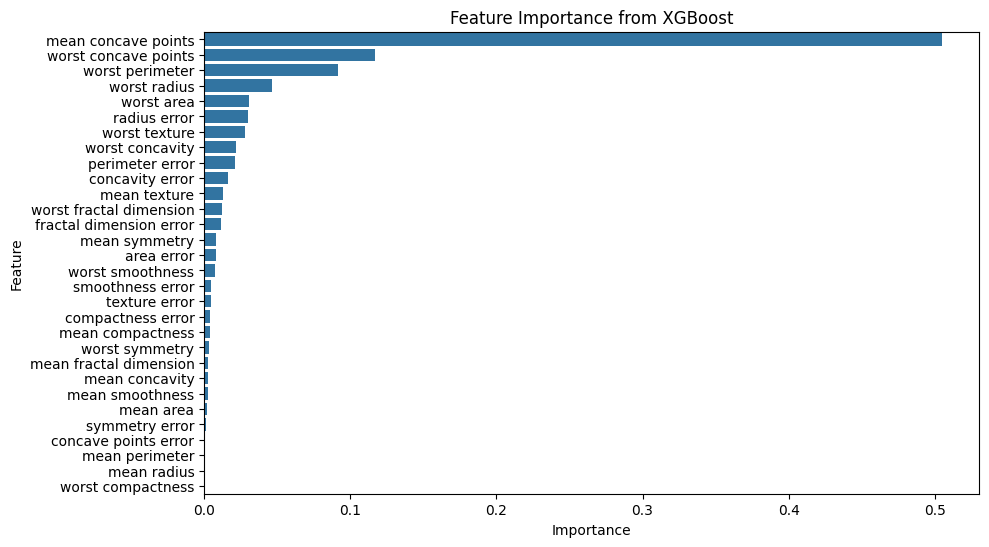

In [114]:
importances = xgb_model.feature_importances_

feature_importance_df = pd.DataFrame({'Feature': X.columns, 'Importance': importances})
feature_importance_df = feature_importance_df.sort_values(by='Importance', ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=feature_importance_df)
plt.title('Feature Importance from XGBoost')
plt.show()


### Advantages of XGBoost:
- **Performance**: XGBoost is known for its speed and accuracy, often outperforming other algorithms in competitions and real-world applications.
- **Regularization**: It includes L1 (Lasso) and L2 (Ridge) regularization to prevent overfitting.
- **Parallelization**: XGBoost uses parallel computing to speed up the training process, making it efficient for large datasets.
- **Handling Missing Values**: XGBoost can handle missing values internally, making it robust to incomplete dta.


## K-Fold Validation - Random Forests

K-Fold Cross-Validation is a popular technique for evaluating a model's performance on a dataset. Instead of dividing the data into a single training and test split, K-Fold Cross-Validation splits the data multiple times, which provides a more reliable performance estimate. Here’s how it works:

1. **Splitting into Folds**: The dataset is divided into `k` subsets (or "folds"). For example, if `k=5`, the data is split into 5 equal parts.

2. **Training and Evaluation**: For each fold:
   - One of the `k` folds is used as the validation set.
   - The remaining `k-1` folds are used as the training set.
   - The model is trained on the training set and evaluated on the validation set, and the accuracy (or other metric) is recorded.
   
3. **Repeating Across Folds**: This process is repeated `k` times, with each fold taking a turn as the validation set.

4. **Calculating Average Performance**: Finally, we take the average of the metric scores across all `k` folds. This average provides a more stable estimate of the model’s performance than a single train-test split.

### Why Use K-Fold Cross-Validation?
K-Fold Cross-Validation provides several advantages:
- **Stability**: By testing the model across different subsets of the data, we get a more consistent estimate of its performance.
- **Effective for Small Datasets**: Instead of dedicating a large part of the data for testing, K-Fold Cross-Validation allows the model to be evaluated on multiple parts of the data, making it ideal for small datasets.
- **Reduces Overfitting**: Using multiple training and validation sets reduces the likelihood of overfitting to any particular train-test split.

### Example with 5-Fold Cross-Validation
In our example, we’ll use 5-Fold Cross-Validation with a Random Forest model to evaluate its performance on our dataset.

We’ll perform the following steps:
1. Initialize a `KFold` object with 5 splits.
2. For each fold, train the model on the training set and evaluate it on the validation set.
3. Store the accuracy score for each fold, then calculate and print the average accuracy.

---



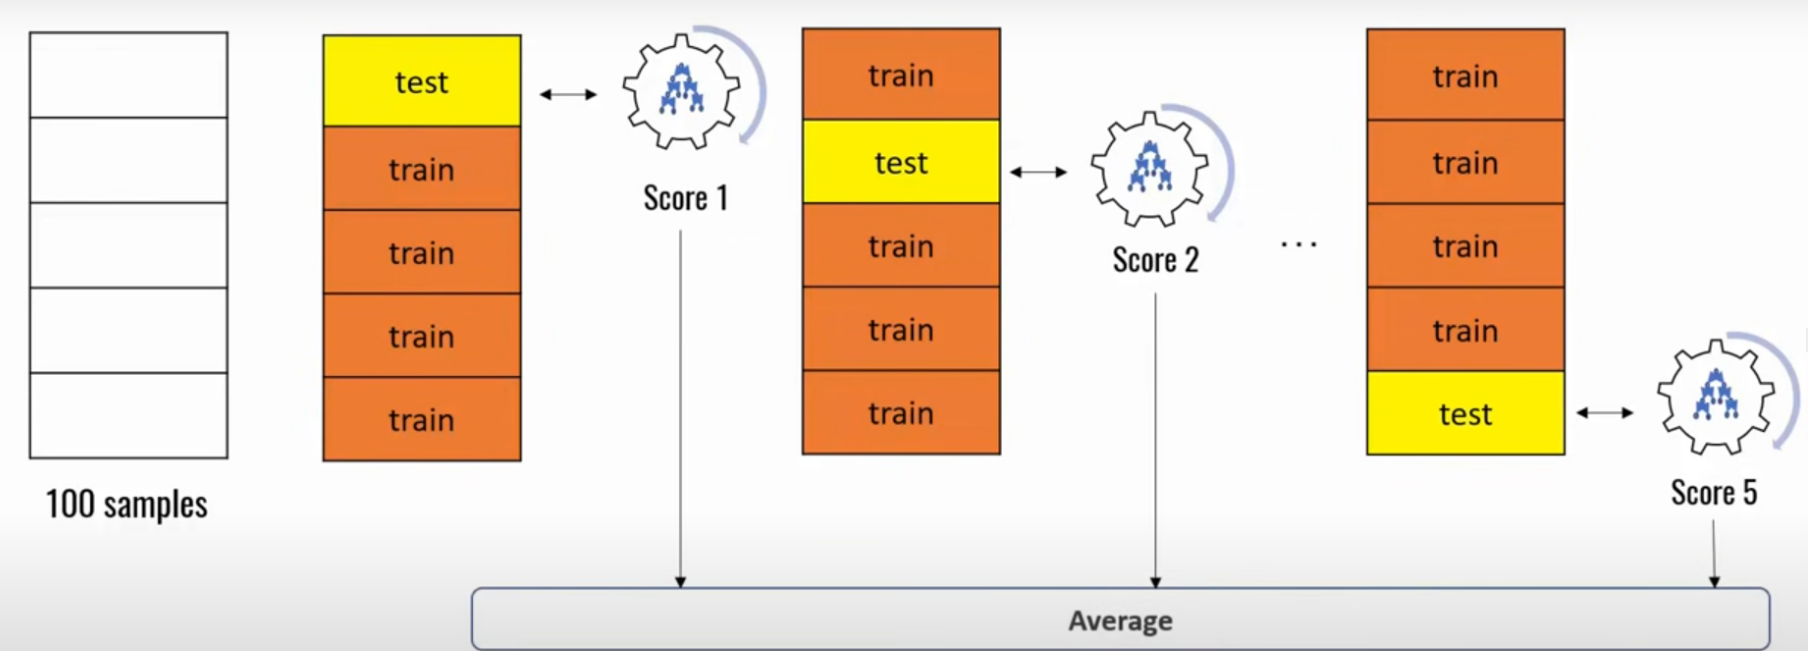

In [115]:
from sklearn.model_selection import KFold, cross_val_score

rf = RandomForestClassifier(random_state=42)

kf = KFold(n_splits=5, shuffle=True, random_state=42)
fold_accuracies = []

for train_index, val_index in kf.split(X):
    X_train_fold, X_val_fold = X.iloc[train_index], X.iloc[val_index]
    y_train_fold, y_val_fold = y.iloc[train_index], y.iloc[val_index]

    rf.fit(X_train_fold, y_train_fold)
    val_pred = rf.predict(X_val_fold)
    fold_accuracy = accuracy_score(y_val_fold, val_pred)
    fold_accuracies.append(fold_accuracy)

print("Manual K-Fold Accuracies:", fold_accuracies)
print("Mean Accuracy:", np.mean(fold_accuracies))


Manual K-Fold Accuracies: [0.956140350877193, 0.9649122807017544, 0.9385964912280702, 0.9649122807017544, 0.9646017699115044]
Mean Accuracy: 0.9578326346840551


## Stratified K-Fold Cross-Validation

**Stratified K-Fold Cross-Validation** is a variation of K-Fold Cross-Validation, designed to ensure that each fold has a similar distribution of each target class. This is particularly useful for **classification tasks with imbalanced classes**.

### Key Differences from Regular K-Fold:
- In **K-Fold Cross-Validation**, data is split into `k` folds without regard to the class distribution, which can lead to uneven representation of classes in each fold.
- In **Stratified K-Fold Cross-Validation**, each fold maintains the same class distribution as the entire dataset, ensuring more balanced and consistent training and evaluation.

### Why Use Stratified K-Fold?
Stratified K-Fold is ideal for classification problems, especially with imbalanced data, because it:
- Provides more reliable estimates by keeping class proportions consistent across folds.
- Reduces the risk of having a validation fold with too few samples from a minority class, which could skew the evaluation.

---


In [116]:
from sklearn.model_selection import StratifiedKFold

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
fold_accuracies = []

for train_index, val_index in kf.split(X, y):
    X_train_fold, X_val_fold = X.iloc[train_index], X.iloc[val_index]
    y_train_fold, y_val_fold = y.iloc[train_index], y.iloc[val_index]

    rf.fit(X_train_fold, y_train_fold)
    val_pred = rf.predict(X_val_fold)
    fold_accuracy = accuracy_score(y_val_fold, val_pred)
    fold_accuracies.append(fold_accuracy)

print("Stratified K-Fold Accuracies:", fold_accuracies)
print("Mean Accuracy:", np.mean(fold_accuracies))


Stratified K-Fold Accuracies: [0.956140350877193, 0.9649122807017544, 0.9385964912280702, 0.9649122807017544, 0.9646017699115044]
Mean Accuracy: 0.9578326346840551


## K-Fold and Stratified K-Fold Cross-Validation Using `cross_val_score`

The `cross_val_score` function from `sklearn.model_selection` is a convenient way to perform K-Fold or Stratified K-Fold Cross-Validation in one line. This function:
- Splits the dataset automatically based on the specified cross-validation strategy.
- Trains the model on each fold.
- Returns an array of scores (e.g., accuracy) for each fold.

### 1. K-Fold Cross-Validation

In [117]:
from sklearn.model_selection import cross_val_score, KFold
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(random_state=42)

kf = KFold(n_splits=5, shuffle=True, random_state=42)

kfold_scores = cross_val_score(rf, X, y, cv=kf, scoring='accuracy')
print("K-Fold Cross-Validation Accuracies:", kfold_scores)
print("Mean Accuracy:", kfold_scores.mean())

K-Fold Cross-Validation Accuracies: [0.95614035 0.96491228 0.93859649 0.96491228 0.96460177]
Mean Accuracy: 0.9578326346840551


### 2. Stratified K-Fold Cross-Validation

In [118]:
from sklearn.model_selection import StratifiedKFold

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

stratified_scores = cross_val_score(rf, X, y, cv=skf, scoring='accuracy')
print("Stratified K-Fold Cross-Validation Accuracies:", stratified_scores)
print("Mean Accuracy:", stratified_scores.mean())

Stratified K-Fold Cross-Validation Accuracies: [0.96491228 0.93859649 0.95614035 0.94736842 0.97345133]
Mean Accuracy: 0.9560937742586555


---
## Hyperparameter Tuning

### Hyperparameter Tuning for Random Forest with Grid Search

In machine learning, finding the best hyperparameters for a model can significantly improve its performance. **Grid Search** is one of the most common techniques for hyperparameter tuning. It systematically tests multiple combinations of parameters and finds the one that produces the best results according to a chosen metric (e.g., accuracy).

Helpful Link: https://machinelearningmastery.com/hyperparameter-optimization-with-random-search-and-grid-search/


In [119]:
randomforest_model = RandomForestClassifier(random_state=42)

In [120]:
param_grid = {
    'n_estimators': [51, 101, 201],
    'max_depth': [3, 5, 10, None]
}

- `n_estimators`: Number of trees in the forest (e.g., 51, 101, 201).
- `max_depth`: Maximum depth of each tree (e.g., 3, 5, 10, or unlimited with `None`).

In [121]:
grid_search = GridSearchCV(estimator=randomforest_model, param_grid=param_grid, cv=5, scoring='accuracy')
grid_search.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestC...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'max_depth': [3, 5, ...], 'n_estimators': [51, 101, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: intControls the verbosity: the higher, the more messages.- >1 : the computation time for each fold and parameter candidate is displayed;- >2 : the score is also displaye

In [122]:
print('Best Parameters are: {}'.format(grid_search.best_params_))

Best Parameters are: {'max_depth': 10, 'n_estimators': 201}


In [123]:
best_randomforest_model = grid_search.best_estimator_

In [124]:
randomforest_predictions = best_randomforest_model.predict(X_test)

print("Random Forest Accuracy is {}".format(accuracy_score(y_test, randomforest_predictions)))
print(classification_report(y_test, randomforest_predictions))

Random Forest Accuracy is 0.9707602339181286
              precision    recall  f1-score   support

         0.0       0.98      0.94      0.96        63
         1.0       0.96      0.99      0.98       108

    accuracy                           0.97       171
   macro avg       0.97      0.96      0.97       171
weighted avg       0.97      0.97      0.97       171



### Hyperparameter Tuning for XGBoost

In [125]:
xgboost_model = XGBClassifier(eval_metric='logloss', random_state=42)

In [126]:
param_grid_xgb = {
    'n_estimators': [51, 101, 201],
    'max_depth': [3, 5, 10]
}

- `n_estimators`: Number of boosting rounds (e.g., 51, 101, 201).
- `max_depth`: Maximum tree depth for base learners (e.g., 3, 5, 10).

In [127]:
grid_search_xgboost = GridSearchCV(estimator=xgboost_model, param_grid=param_grid_xgb, cv=5, scoring='accuracy')
grid_search_xgboost.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","XGBClassifier...ree=None, ...)"
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'max_depth': [3, 5, ...], 'n_estimators': [51, 101, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: intControls the verbosity: the higher, the more messages.- >1 : the computation time for each fold and parameter candidate is displayed;- >2 : the score is also displa

In [128]:
print("Best Parameters for XGBoost are {}".format(grid_search_xgboost.best_params_))

Best Parameters for XGBoost are {'max_depth': 3, 'n_estimators': 201}


In [129]:
best_xgboost_model = grid_search_xgboost.best_estimator_
xgboost_predictions = best_xgboost_model.predict(X_test)

print("XGBoost Accuracy is {}".format(accuracy_score(y_test, xgboost_predictions)))
print(classification_report(y_test, xgboost_predictions))

XGBoost Accuracy is 0.9707602339181286
              precision    recall  f1-score   support

         0.0       0.95      0.97      0.96        63
         1.0       0.98      0.97      0.98       108

    accuracy                           0.97       171
   macro avg       0.97      0.97      0.97       171
weighted avg       0.97      0.97      0.97       171



## Regression using Ensemble Methods

In [130]:
diabetes = load_diabetes()

In [131]:
diabetes_df = pd.DataFrame(diabetes.data, columns=diabetes.feature_names)
diabetes_df['target'] = diabetes.target

In [132]:
diabetes_df.head()

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


**age**: Age of the individual (standardized).<br>
**sex**: Gender (standardized, where 1 usually represents male and -1 represents female).<br>
**bmi**: Body Mass Index (BMI), a measure of body fat based on height and weight (standardized).<br>
**bp**: Average blood pressure (standardized).<br>
**s1**: T-Cells (a type of white blood cell, standardized).<br>
**s2**: Low-density lipoproteins (LDL) cholesterol levels (standardized).<br>
**s3**: High-density lipoproteins (HDL) cholesterol levels (standardized).<br>
**s4**: Total cholesterol to HDL ratio (standardized).<br>
**s5**: Log of serum triglycerides level (standardized).<br>
**s6**: Blood sugar level (standardized).<br>

In [133]:
X = diabetes_df.drop(columns='target')
y = diabetes_df['target']

In [134]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

### Decision Trees

#### Decision Trees for Regression Tasks
In regression, decision trees predict continuous values by splitting data into groups and using the mean value of each group as the prediction.

#### How Regression Trees Work
  - Tree looks for splits that minimize variance in target values
  - Uses Mean Squared Error (MSE): `MSE = Σ(actual - predicted)²/n`
  - Each leaf node's prediction is the mean of training samples in that node

In [135]:
decision_tree_regressor = DecisionTreeRegressor(max_depth=3, random_state=42)

In [136]:
decision_tree_regressor.fit(X_train, y_train)

,"criterion criterion: {""squared_error"", ""friedman_mse"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""friedman_mse"", which usesmean squared error with Friedman's improvement score for potentialsplits, ""absolute_error"" for the mean absolute error, which minimizesthe L1 loss using the median of each terminal node, and ""poisson"" whichuses reduction in the half mean Poisson deviance to find splits... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 0.24 Poisson deviance criterion.",'squared_error'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.For an example of how ``max_depth`` influences the model, see:ref:`sphx_glr_auto_examples_tree_plot_tree_regression.py`.",3
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary ` for details.",42
,"max_leaf

<Figure size 1200x800 with 0 Axes>

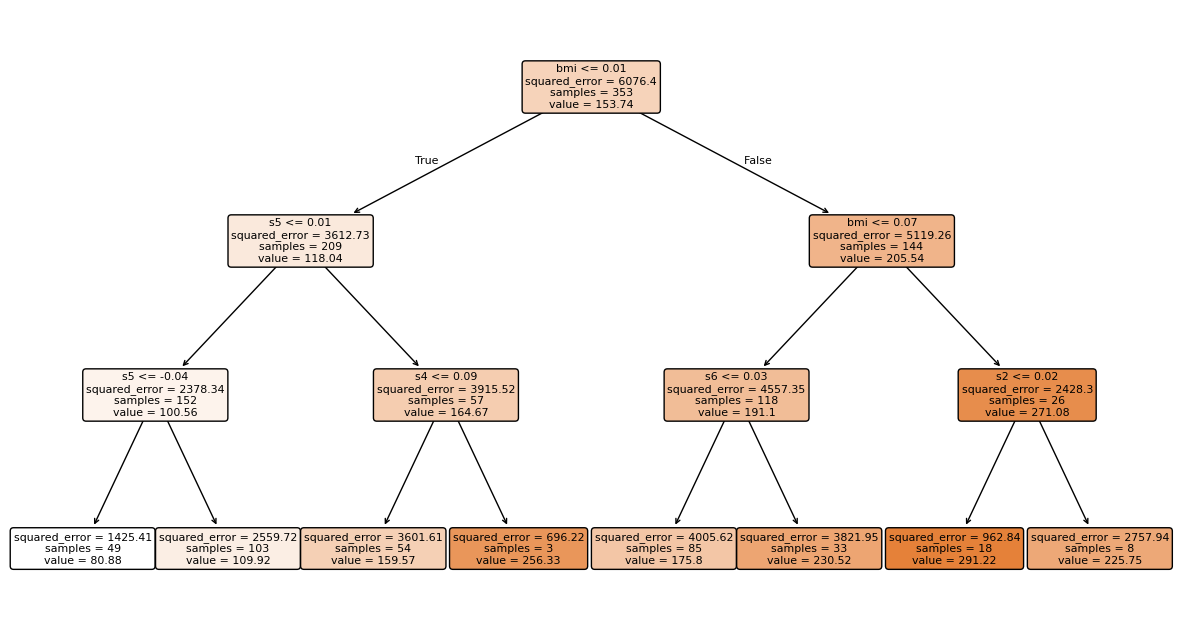

In [137]:
plt.figure(figsize=(12, 8))
plt.figure(figsize=(15, 8))
plot_tree(
    decision_tree_regressor,
    rounded=True,
    precision=2,
    filled=True,
    feature_names=diabetes_df.columns,
)
plt.show()

In [138]:
def evaluate_model(y_true, y_pred):
    rmse = root_mean_squared_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    print("The RMSE and the R2 values of the model are: {}, {}".format(rmse, r2))

In [139]:
decision_tree_predictions = decision_tree_regressor.predict(X_test)

In [140]:
evaluate_model(y_test, decision_tree_predictions)

The RMSE and the R2 values of the model are: 59.60454104616319, 0.3294451571119206


### Random Forests

In [141]:
randomforest_model = RandomForestRegressor(random_state=42)

In [142]:
param_grid = {
    'n_estimators': [51, 101, 201],
    'max_depth': [3, 5, 10, None]
}

In [143]:
grid_search = GridSearchCV(estimator=randomforest_model, param_grid=param_grid, cv=5, scoring='r2')
grid_search.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestR...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'max_depth': [3, 5, ...], 'n_estimators': [51, 101, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'r2'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: intControls the verbosity: the higher, the more messages.- >1 : the computation time for each fold and parameter candidate is displayed;- >2 : the score is also displayed;- >3

In [144]:
print('Best Parameters are: {}'.format(grid_search.best_params_))

Best Parameters are: {'max_depth': 3, 'n_estimators': 201}


In [145]:
best_randomforest_model = grid_search.best_estimator_

In [146]:
randomforest_predictions = best_randomforest_model.predict(X_test)

In [147]:
evaluate_model(y_test, randomforest_predictions)

The RMSE and the R2 values of the model are: 52.66598846566669, 0.47647661435097044


### XGBoost

In [148]:
xgboost_model = XGBRegressor(random_state=42)

In [149]:
param_grid = {
    'n_estimators': [50, 100, 200],
    'learning_rate': [0.01, 0.1, 0.2],
    'max_depth': [3, 5, 7],
}

In [150]:
grid_search_xgboost = GridSearchCV(estimator=xgboost_model, param_grid=param_grid, cv=5, scoring='r2')
grid_search_xgboost.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","XGBRegressor(...ree=None, ...)"
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'learning_rate': [0.01, 0.1, ...], 'max_depth': [3, 5, ...], 'n_estimators': [50, 100, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'r2'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: intControls the verbosity: the higher, the more messages.- >1 : the computation time for each fold and parameter candidate is displayed;- 

In [151]:
best_xgboost_model = grid_search_xgboost.best_estimator_

In [152]:
xgboost_predictions = best_xgboost_model.predict(X_test)

In [153]:
evaluate_model(y_test, xgboost_predictions)

The RMSE and the R2 values of the model are: 53.293562807707026, 0.4639255401595046


# **Lab Assignment**
1. Load the 'adult.csv' dataset into a pandas dataframe (done for you).
2. Perform preprocessing, handling missing values, normalizing, and encoding categorical variables to prepare the dataset for training.
3. Use single decision trees and at least one bagging and boosting model each to implement the binary classification task to predict whether an adult earns more than $50k a year. You can experiment with other boosting models like LightGBM, AdaBoost, CatBoost, etc if you want.
4. Use K-fold Validation and Hyperparameter Tuning to further improve your models and discuss all the results.

In [154]:
import pandas as pd
from sklearn.model_selection import train_test_split

# Use pandas to read the "adult.csv" file as a dataframe
df = pd.read_csv("adult.csv")

# Split the dataframe into input and target
X = df.drop("income", axis=1)
y = df["income"]

In [155]:
X.head()

,age,workclass,fnlwgt,education,educational-num,marital-status,occupation,relationship,race,gender,capital-gain,capital-loss,hours-per-week,native-country
0,25,Private,226802,11th,7,Never-married,Machine-op-inspct,Own-child,Black,Male,0,0,40,United-States
1,38,Private,89814,HS-grad,9,Married-civ-spouse,Farming-fishing,Husband,White,Male,0,0,50,United-States
2,28,Local-gov,336951,Assoc-acdm,12,Married-civ-spouse,Protective-serv,Husband,White,Male,0,0,40,United-States
3,44,Private,160323,Some-college,10,Married-civ-spouse,Machine-op-inspct,Husband,Black,Male,7688,0,40,United-States
4,18,?,103497,Some-college,10,Never-married,?,Own-child,White,Female,0,0,30,United-States


In [156]:
# Get the number of rows and columns in the dataset
X.shape

(48842, 14)

In [157]:
# Get information about the dataset including data types for the parameters
X.info()

<class 'pandas.DataFrame'>
RangeIndex: 48842 entries, 0 to 48841
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   age              48842 non-null  int64
 1   workclass        48842 non-null  str  
 2   fnlwgt           48842 non-null  int64
 3   education        48842 non-null  str  
 4   educational-num  48842 non-null  int64
 5   marital-status   48842 non-null  str  
 6   occupation       48842 non-null  str  
 7   relationship     48842 non-null  str  
 8   race             48842 non-null  str  
 9   gender           48842 non-null  str  
 10  capital-gain     48842 non-null  int64
 11  capital-loss     48842 non-null  int64
 12  hours-per-week   48842 non-null  int64
 13  native-country   48842 non-null  str  
dtypes: int64(6), str(8)
memory usage: 5.2 MB


In [158]:
# Split the dataset into training and testing data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

In [159]:
X_train.shape

(34189, 14)

In [160]:
X_test.shape

(14653, 14)

In [161]:
# Your code:
